In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uint64_csv_file = "single_thread_thp.alex_lipp_preload_1_100_uint64.csv"
dataset_csv_file = "single_thread_thp.alex_lipp_preload_1_100_dataset.csv"

# read data and group by key_path, index_type, init_table_size, test_suite
df = pd.read_csv(uint64_csv_file)
df_= pd.read_csv(dataset_csv_file)
df = pd.concat([df, df_])

# group by as key_path index_type init_table_size test_suite
df_grouped = df.groupby(["key_path", "index_type", "init_table_size", "test_suite", "preload_suite"])

# construct a new dataframe for each group
transformed_df = pd.DataFrame(
    columns=[
        "key_path",
        "index_type",
        "init_table_size",
        "test_suite",
        "preload_suite",
        "insert_throughput_avg",
        "insert_throughput_min",
        "insert_throughput_max",
        "insert_throughput_stdv",
        "insert_throughput_cv",
        "read_throughput_avg",
        "read_throughput_min",
        "read_throughput_max",
        "read_throughput_stdv",
        "read_throughput_cv",
        "memory_consumption",
    ]
)

for name, group in df_grouped:
    key_path, index_type, init_table_size, test_suite, preload_suite = name
    insert_throughput_avg = group.loc[group["insert_ratio"] == 1, "throughput"].mean()
    insert_throughput_min = group.loc[group["insert_ratio"] == 1, "throughput"].min()
    insert_throughput_max = group.loc[group["insert_ratio"] == 1, "throughput"].max()
    insert_throughput_stdv = group.loc[group["insert_ratio"] == 1, "throughput"].std()
    insert_throughput_cv = insert_throughput_stdv / insert_throughput_avg
    read_throughput_avg = group.loc[group["read_ratio"] == 1, "throughput"].mean()
    read_throughput_min = group.loc[group["read_ratio"] == 1, "throughput"].min()
    read_throughput_max = group.loc[group["read_ratio"] == 1, "throughput"].max()
    read_throughput_stdv = group.loc[group["read_ratio"] == 1, "throughput"].std()
    read_throughput_cv = read_throughput_stdv / read_throughput_avg
    memory_consumption = group["memory_consumption"].mean()
    transformed_df.loc[len(transformed_df)] = [
        key_path,
        index_type,
        init_table_size,
        test_suite,
        preload_suite,
        insert_throughput_avg,
        insert_throughput_min,
        insert_throughput_max,
        insert_throughput_stdv,
        insert_throughput_cv,
        read_throughput_avg,
        read_throughput_min,
        read_throughput_max,
        read_throughput_stdv,
        read_throughput_cv,
        memory_consumption,
    ]

csv_file="single_thread_thp.csv"
df = pd.read_csv(csv_file)
df_grouped = df.groupby(["key_path", "index_type", "init_table_size", "test_suite"])

transformed_df["original_read_throughput_avg"] = np.nan
transformed_df["read_throughput_avg_change_ratio"] = np.nan
for index, row in transformed_df.iterrows():
    key_path = row["key_path"]
    index_type = row["index_type"]
    init_table_size = row["init_table_size"]
    test_suite = row["test_suite"]
    original_case_group= df_grouped.get_group((key_path, index_type, init_table_size, test_suite))
    original_read_throughput_avg = original_case_group.loc[original_case_group["read_ratio"] == 1, "throughput"].mean()
    read_throughput_avg_change_ratio = (row["read_throughput_avg"] - original_read_throughput_avg) / original_read_throughput_avg
    transformed_df.loc[index, "original_read_throughput_avg"] = original_read_throughput_avg
    transformed_df.loc[index, "read_throughput_avg_change_ratio"] = read_throughput_avg_change_ratio

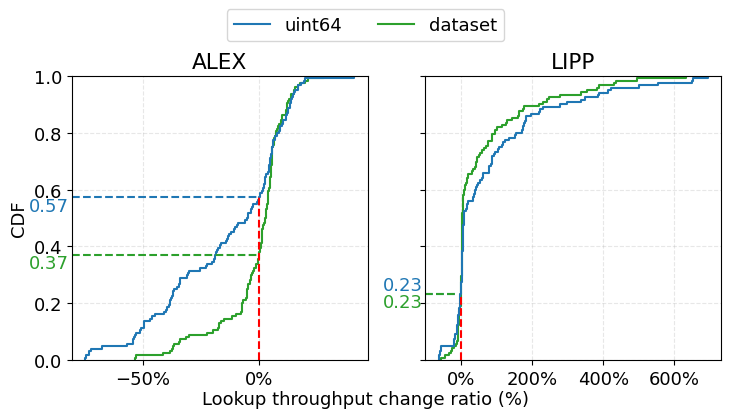

In [47]:
import matplotlib.ticker as mticker
import seaborn as sns
import matplotlib.pyplot as plt
def get_official_name(str):
    if str == "btree":
        return "B+tree"
    elif str == "btreeolc":
        return "B+tree\nOLC"
    elif str == "art":
        return "ART"
    elif str == "artolc":
        return "ART\nOLC"
    elif str == "alex":
        return "ALEX"
    elif str == "alexolc":
        return "ALEX\nOLC"
    elif str == "lipp":
        return "LIPP"
    elif str == "lippolc":
        return "LIPP\nOLC"
    elif str == "dytis":
        return "DyTIS"
    elif str == "dili":
        return "DILI"
    elif str == "finedex":
        return "FineDex"
    elif str == "sali":
        return "SALI"
    elif str == "datasets/linear":
        return "Linear"
    elif str == "datasets/covid":
        return "Covid"
    elif str == "datasets/fb":
        return "Face"
    elif str == "datasets/fb-1":
        return "Face"
    elif str == "datasets/osm":
        return "OSM"
# 过滤数据
index_types = ["alex", "lipp"]
filtered_df = transformed_df[(transformed_df["index_type"].isin(index_types))]

# 绘制 CDF 图
plt.rcParams.update({"font.size": 13})
fig, axs = plt.subplots(1, 2, figsize=(7.5, 4), sharey=True)
filtered_df['Preload Method'] = filtered_df['preload_suite'].replace({33: 'uint64', 34: 'dataset'}) + ' - ' + filtered_df['index_type'].apply(get_official_name)
palette = {"uint64 - ALEX": "#1f77b4", "dataset - ALEX": "#2ca02c", "uint64 - LIPP": "#1f77b4", "dataset - LIPP": "#2ca02c"}

sns.ecdfplot(
    data=filtered_df[filtered_df['index_type'] == 'alex'],
    x="read_throughput_avg_change_ratio",
    hue="Preload Method",
    ax=axs[0],
    palette=palette,
    legend=False
)
sns.ecdfplot(
    data=filtered_df[filtered_df['index_type'] == 'lipp'],
    x="read_throughput_avg_change_ratio",
    hue="Preload Method",
    ax=axs[1],
    palette=palette,
    legend=False
)

alex_33_y_value_at_0 = (filtered_df[(filtered_df['index_type'] == 'alex') & (filtered_df['preload_suite'] == 33)]['read_throughput_avg_change_ratio'] < 0).sum() / len(filtered_df[(filtered_df['index_type'] == 'alex') & (filtered_df['preload_suite'] == 33)])
alex_34_y_value_at_0 = (filtered_df[(filtered_df['index_type'] == 'alex') & (filtered_df['preload_suite'] == 34)]['read_throughput_avg_change_ratio'] < 0).sum() / len(filtered_df[(filtered_df['index_type'] == 'alex') & (filtered_df['preload_suite'] == 34)])
lipp_33_y_value_at_0 = (filtered_df[(filtered_df['index_type'] == 'lipp') & (filtered_df['preload_suite'] == 33)]['read_throughput_avg_change_ratio'] < 0).sum() / len(filtered_df[(filtered_df['index_type'] == 'lipp') & (filtered_df['preload_suite'] == 33)])
lipp_34_y_value_at_0 = (filtered_df[(filtered_df['index_type'] == 'lipp') & (filtered_df['preload_suite'] == 34)]['read_throughput_avg_change_ratio'] < 0).sum() / len(filtered_df[(filtered_df['index_type'] == 'lipp') & (filtered_df['preload_suite'] == 34)])

axs[0].plot([0, 0], [0, max(alex_33_y_value_at_0,alex_34_y_value_at_0)], 'r--')  # 垂直虚线
axs[1].plot([0, 0], [0, max(lipp_33_y_value_at_0,lipp_34_y_value_at_0)], 'r--')  # 垂直虚线
axs[0].axhline(y=alex_33_y_value_at_0, xmin=0, xmax=0.63, color='#1f77b4', linestyle='--')  # 水平虚线
axs[0].axhline(y=alex_34_y_value_at_0, xmin=0, xmax=0.63, color='#2ca02c', linestyle='--')  # 水平虚线
axs[1].axhline(y=lipp_33_y_value_at_0, xmin=0, xmax=0.1, color='#1f77b4', linestyle='--')  # 水平虚线
axs[1].axhline(y=lipp_34_y_value_at_0, xmin=0, xmax=0.1, color='#2ca02c', linestyle='--')  # 水平虚线
axs[0].text(-0.99, alex_33_y_value_at_0-0.03, f'{alex_33_y_value_at_0:.2f}', color='#1f77b4', va='center')
axs[0].text(-0.99, alex_34_y_value_at_0-0.03, f'{alex_34_y_value_at_0:.2f}', color='#2ca02c', va='center')
axs[1].text(-2.22, lipp_33_y_value_at_0+0.03, f'{lipp_33_y_value_at_0:.2f}', color='#1f77b4', va='center')
axs[1].text(-2.22, lipp_34_y_value_at_0-0.03, f'{lipp_34_y_value_at_0:.2f}', color='#2ca02c', va='center')


# 添加网格
axs[0].grid(True, linestyle='--', alpha=0.3)
axs[1].grid(True, linestyle='--', alpha=0.3)

# 设置 x 轴为百分比格式
axs[0].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
axs[1].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
plt.gca().yaxis.set_major_locator(mticker.MultipleLocator(0.2))

# 移除子图的 x 轴标题
axs[0].set_xlabel("")
axs[1].set_xlabel("")

axs[0].set_title('ALEX')
axs[1].set_title('LIPP')

# 设置 y 轴标题
axs[0].set_ylabel("CDF")
axs[1].set_ylabel("CDF")

# 设置 fig 层面的 x 轴标题
fig.text(0.5, 0.04, 'Lookup throughput change ratio (%)', ha='center')

# 手动设置图例，绿色线为 uint64，红色线为 dataset
from matplotlib.lines import Line2D
custom_lines = [Line2D([0], [0], color='#1f77b4'),
                Line2D([0], [0], color='#2ca02c')]
fig.legend(custom_lines, ['uint64', 'dataset'], loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.05))
plt.tight_layout()
plt.subplots_adjust(top=0.86)
plt.subplots_adjust(bottom=0.15)
# plt.show()
plt.savefig("./fig/alex_lipp_read_throughput_change_ratio_under_preload.pdf",bbox_inches="tight", transparent=True)